In [ ]:
MAME: KUSHI NIRANJANA
SRN: PES2UG24CS245

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB   (W x H x C x B)
frame_bytes = 1920 * 1080 * 3 * 1
frame_mb = frame_bytes / 1024**2

# TODO 2: frames per camera per day at 30 fps   (N = f x T)
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = 400 * frames_per_day * frame_bytes / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_frame_bytes = 640 * 360 * 3
small_frames_per_day = 10 * 24 * 60 * 60
fleet_tb_small = 400 * small_frames_per_day * small_frame_bytes / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ Spatially, we’d lose fine detail like a face, a number plate or a logo on clothing. At 360p only about 11% of the pixels are left, and upscaling later just interpolates (Slide 13), so it can’t bring that detail back. Temporally, dropping to 10 fps means a fast event such as someone sprinting or a quick grab falls between frames. Bigger jumps per frame also make it harder to match the same object from frame to frame (the correspondence problem, Slides 36–37), so the direction of motion can become unclear.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

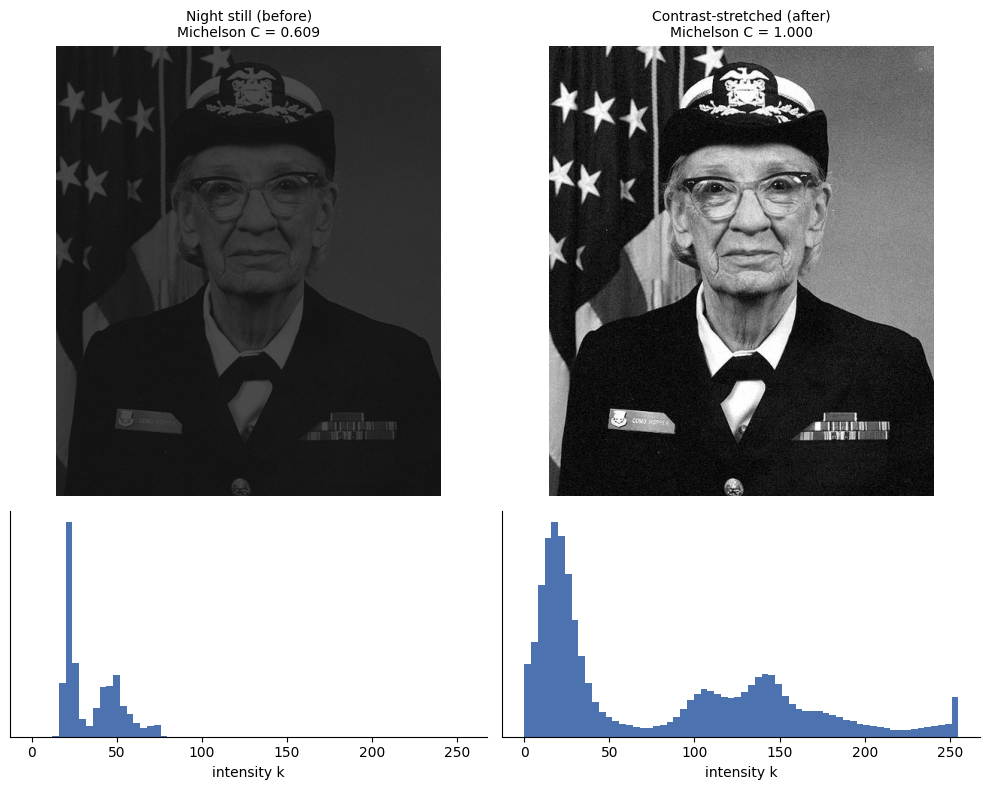

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version (1st pct -> 0, 99th pct -> 255)
stretched = np.clip((night_still - lo) / (hi - lo) * 255, 0, 255)

lo2, hi2 = np.percentile(stretched, [1, 99])
c_after = michelson(hi2, lo2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for col, (im, name, c) in enumerate([(night_still, "Night still (before)", c_before),
                                      (stretched, "Contrast-stretched (after)", c_after)]):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, col].axis("off")
    axes[0, col].set_title(f"{name}\nMichelson C = {c:.3f}", fontsize=10)
    axes[1, col].hist(im.ravel(), bins=64, range=(0, 255), color="#4C72B0")
    axes[1, col].set_yticks([]); axes[1, col].set_xlabel("intensity k")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_
The night image’s histogram is one narrow hump bunched up on the dark (left) side, roughly 20–70, with nothing in the bright range. In the Slide 18 vocabulary that’s a dark, low-contrast image. Stretching made it readable because the same pixel differences got spread over 0–255, so our eyes can finally see them (contrast went from about 0.61 to 1.0). No new information was added, though. A histogram only counts how many pixels have each brightness, not where they are, so the same histogram could belong to a face, a car or random noise.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Person standing: 68.7 s  ->  78.1 s
Person running: 78.6 s  ->  86.0 s
Loud audio impulse: frame 2250 (t = 75.0 s)
Lighting change:    frame 3000 (t = 100.0 s)


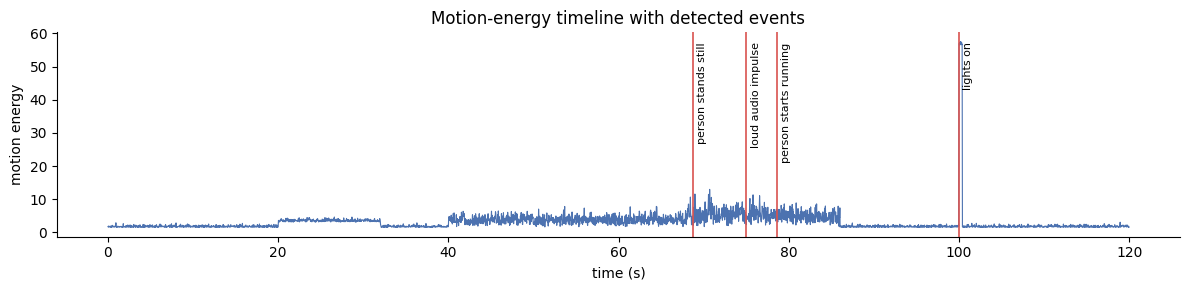

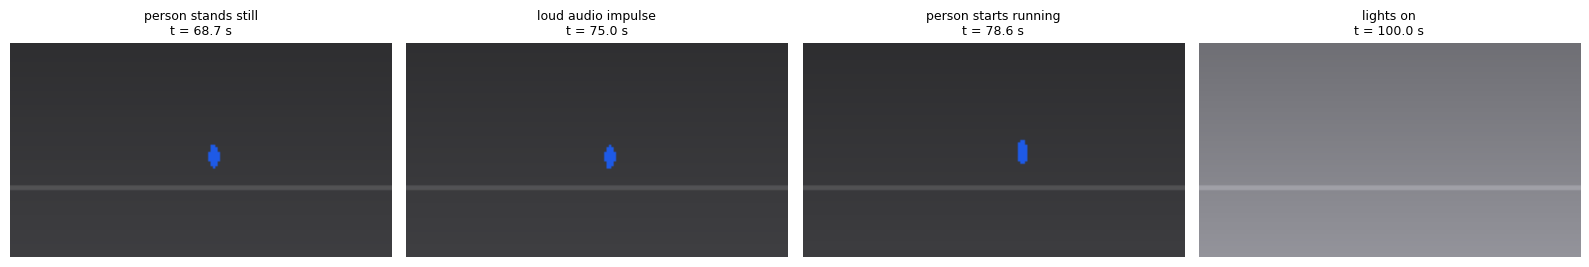

In [4]:
# TODO 1: person speed (px/s) - displacement over a 1-second window (30 frames)
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))

# TODO 2: standing / running time ranges
for name, mask in [("standing", speed < 3), ("running", speed > 25)]:
    t = cctv.time_s[mask.fillna(False)]
    print(f"Person {name}: {t.iloc[0]:.1f} s  ->  {t.iloc[-1]:.1f} s")

# TODO 3: event frame indices
audio_event_idx = int(cctv.index[(cctv.audio_level_db > -20) & (cctv.audio_level_db.shift() <= -20)][0])
lighting_event_idx = int(cctv.index[cctv.mean_brightness.diff() > 40][0])
standing_idx = int(cctv.index[(speed < 3).fillna(False)][0])
running_idx = int(cctv.index[(speed > 25).fillna(False)][0])
print(f"Loud audio impulse: frame {audio_event_idx} (t = {cctv.time_s[audio_event_idx]:.1f} s)")
print(f"Lighting change:    frame {lighting_event_idx} (t = {cctv.time_s[lighting_event_idx]:.1f} s)")

events = sorted([(standing_idx, "person stands still"),
                 (audio_event_idx, "loud audio impulse"),
                 (running_idx, "person starts running"),
                 (lighting_event_idx, "lights on")])

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.8)
for i, label in events:
    ax.axvline(cctv.time_s[i], color="#D9534F", lw=1.2)
    ax.text(cctv.time_s[i] + 0.5, ax.get_ylim()[1] * 0.95, label, rotation=90, va="top", fontsize=8)
ax.set_xlabel("time (s)"); ax.set_ylabel("motion energy")
ax.set_title("Motion-energy timeline with detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(4 * len(events), 2.8))
for ax, (i, label) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[i])); ax.axis("off")
    ax.set_title(f"{label}\nt = {cctv.time_s[i]:.1f} s", fontsize=9)
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_
Uniform keyframes (t = 0, 20, 40, 60, 80, 100 s) would most likely miss the loud bang at 75 s, since it’s a single instant, and also the moment the person stops at about 69 s and starts running at about 79 s. We’d mostly be looking at an empty lot. What I used instead is content-based keyframe selection (Slide 40), which picks frames where something actually changes.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

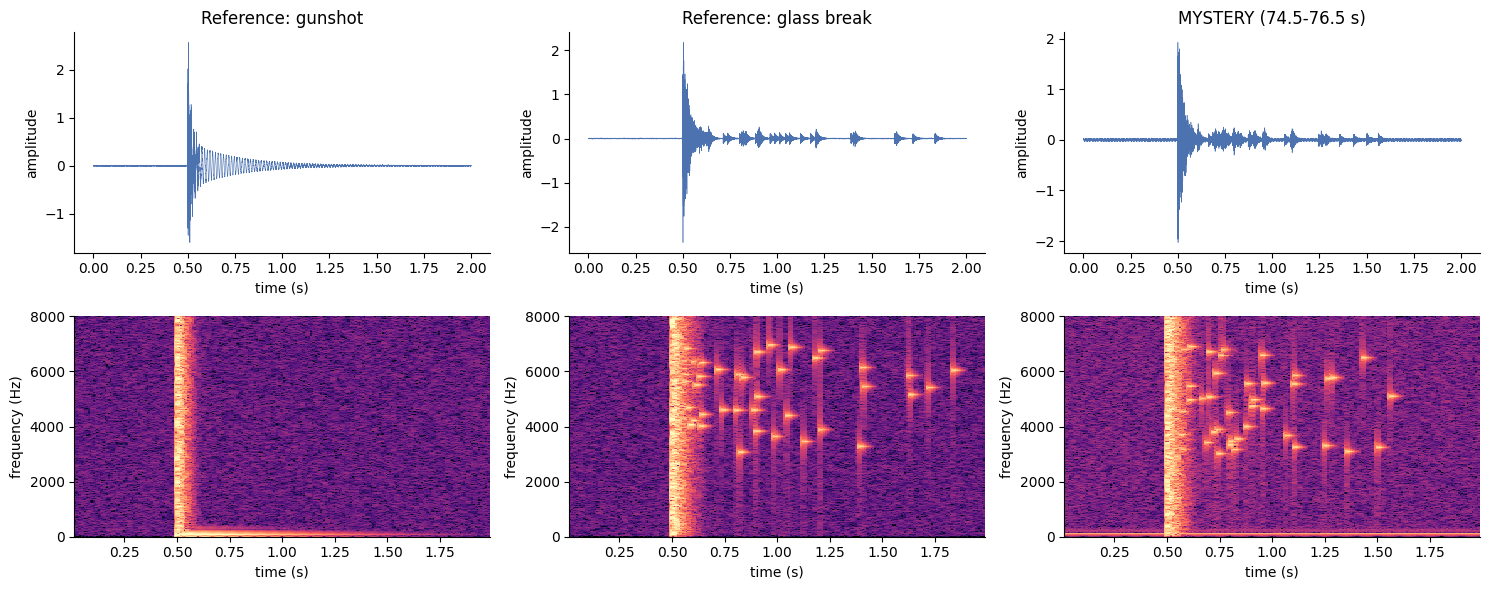

{'Reference: gunshot': np.float64(0.003), 'Reference: glass break': np.float64(0.99), 'MYSTERY (74.5-76.5 s)': np.float64(0.879)}
Verdict: the mystery sound is a GLASS BREAK - 88% of its post-impact energy is above 3 kHz (glass ref 99%, gunshot ref 0%).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row)
t_clip = np.arange(int(2.0 * FS)) / FS
for col, (name, x) in enumerate(clips.items()):
    axes[0, col].plot(t_clip, x, lw=0.4, color="#4C72B0")
    axes[0, col].set_title(name); axes[0, col].set_xlabel("time (s)"); axes[0, col].set_ylabel("amplitude")
    f, tt, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    axes[1, col].pcolormesh(tt, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
    axes[1, col].set_ylim(0, 8000); axes[1, col].set_xlabel("time (s)"); axes[1, col].set_ylabel("frequency (Hz)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact
hf_fraction = {}
for name, x in clips.items():
    seg = x[int((0.5 + 0.2) * FS): int((0.5 + 1.2) * FS)]
    spec = np.abs(np.fft.rfft(seg)) ** 2
    freqs = np.fft.rfftfreq(seg.size, 1 / FS)
    hf_fraction[name] = spec[freqs > 3000].sum() / spec.sum()

print({k: round(v, 3) for k, v in hf_fraction.items()})

# TODO 4: verdict
m = hf_fraction["MYSTERY (74.5-76.5 s)"]
g = hf_fraction["Reference: gunshot"]; gl = hf_fraction["Reference: glass break"]
verdict = "GLASS BREAK" if abs(m - gl) < abs(m - g) else "GUNSHOT"
print(f"Verdict: the mystery sound is a {verdict} - {m:.0%} of its post-impact energy is above 3 kHz "
      f"(glass ref {gl:.0%}, gunshot ref {g:.0%}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
No, not confidently. All three waveforms just show a loud spike followed by decay, so you can tell when something happened but not what it was. The spectrogram adds the three dimensions from Slide 57: time on x, frequency on y, and magnitude as colour. The pattern that decided it was the scattered high-frequency specks (3–7 kHz) lingering after the impact. The gunshot has a short vertical stripe plus a low boom and then nothing, while the mystery clip kept its high-frequency energy (about 88% above 3 kHz, versus about 99% for the glass reference and 0.3% for the gunshot). So it’s glass.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

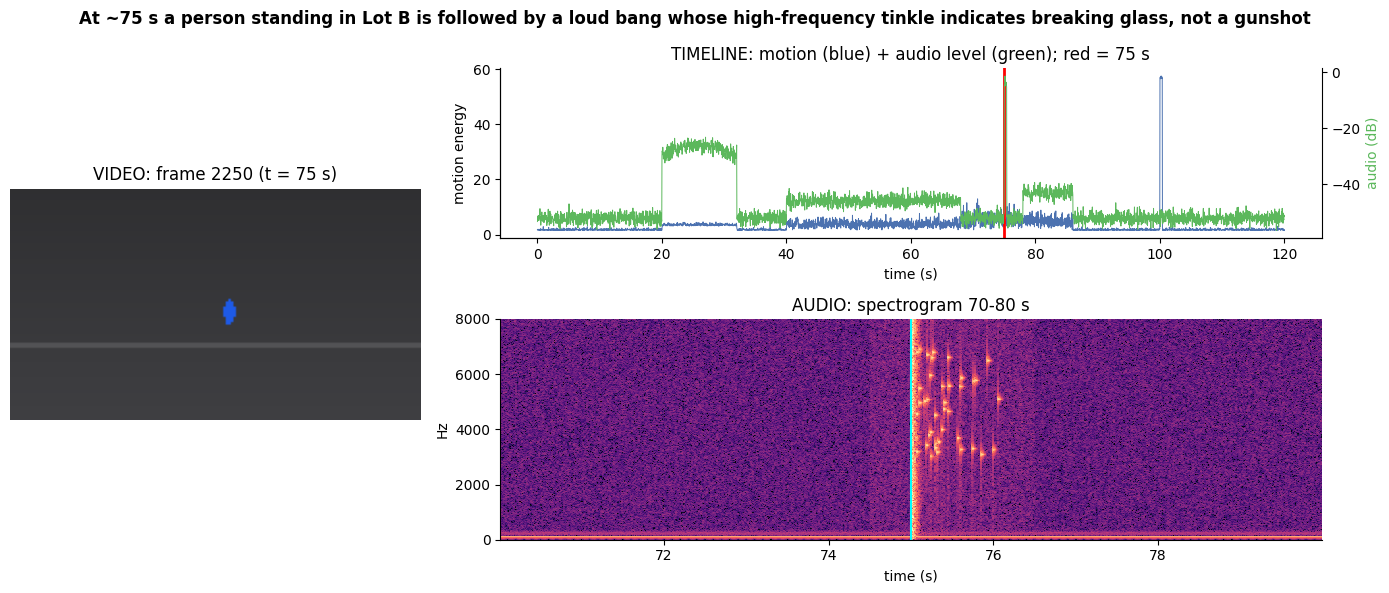

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
i_sel = int(round(t_sel * FPS))
ax_f = fig.add_subplot(gs[:, 0]); ax_t = fig.add_subplot(gs[0, 1]); ax_s = fig.add_subplot(gs[1, 1])

# 1. video frame at t = 75 s
ax_f.imshow(render_frame(cctv.iloc[i_sel])); ax_f.axis("off")
ax_f.set_title(f"VIDEO: frame {i_sel} (t = {t_sel:.0f} s)")

# 2. full 120 s motion + audio timeline with red marker
ax_t.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.7)
ax_t.set_ylabel("motion energy")
ax_t2 = ax_t.twinx(); ax_t2.plot(cctv.time_s, cctv.audio_level_db, color="#5cb85c", lw=0.7)
ax_t2.set_ylabel("audio (dB)", color="#5cb85c")
ax_t2.spines["right"].set_visible(True)
ax_t.axvline(t_sel, color="red", lw=2)
ax_t.set_xlabel("time (s)"); ax_t.set_title("TIMELINE: motion (blue) + audio level (green); red = 75 s")

# 3. spectrogram of x_audio (70-80 s) with the same marker
f, tt, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_s.pcolormesh(tt + t_audio[0], f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
ax_s.axvline(t_sel, color="cyan", lw=1.5); ax_s.set_ylim(0, 8000)
ax_s.set_xlabel("time (s)"); ax_s.set_ylabel("Hz"); ax_s.set_title("AUDIO: spectrogram 70-80 s")

# 4. conclusion-style title
fig.suptitle("At ~75 s a person standing in Lot B is followed by a loud bang whose "
             "high-frequency tinkle indicates breaking glass, not a gunshot", fontsize=12, fontweight="bold")

plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_
The bang would seem to happen at the wrong moment. For example, we’d see the person calmly standing in the frame while the audio already shows breaking glass, or the glass sound would land when the person is already running, so we might wrongly conclude they broke it or reacted before it happened. The timeline and spectrogram panel would show the mistake: the red marker at 75 s would sit away from the audio spike (the spike would be about 2 s off), so the video and audio wouldn’t line up.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_


At about 75 s in Lot B, a person who had been standing still since roughly 69 s was followed by a loud bang, and they ran off from about 79 s to 86 s. The spectrogram shows a long 3–7 kHz tinkle after the impact (88% of the energy above 3 kHz), so it was breaking glass, not a gunshot. I’d put the synchronized view first, because it backs the event up with video, timeline and audio at the same timestamp and follows the structure → pattern → change → event → meaning idea. For storage, uncompressed 1080p/30 fps across 400 cameras is about 5,866 TB/day, so I’d recommend 360p/10 fps for routine footage (about 217 TB/day), keeping full quality around detected events. The one thing it must not sacrifice is the audio with accurate timestamps, since that is what separated glass from a gunshot.